=== CERN / ATLAS Higgs Phase-Boundary Simulation Results ===
1. At Critical Boundary (chi = 0.46, gamma = 0.5): Delta m_H = +0.699 GeV (Detectable Spike!)
2. At Standard LHC Vacuum (chi = 1.40, gamma = 0.5):    Delta m_H = +0.062 GeV (< ATLAS +/- 0.11 GeV limit)


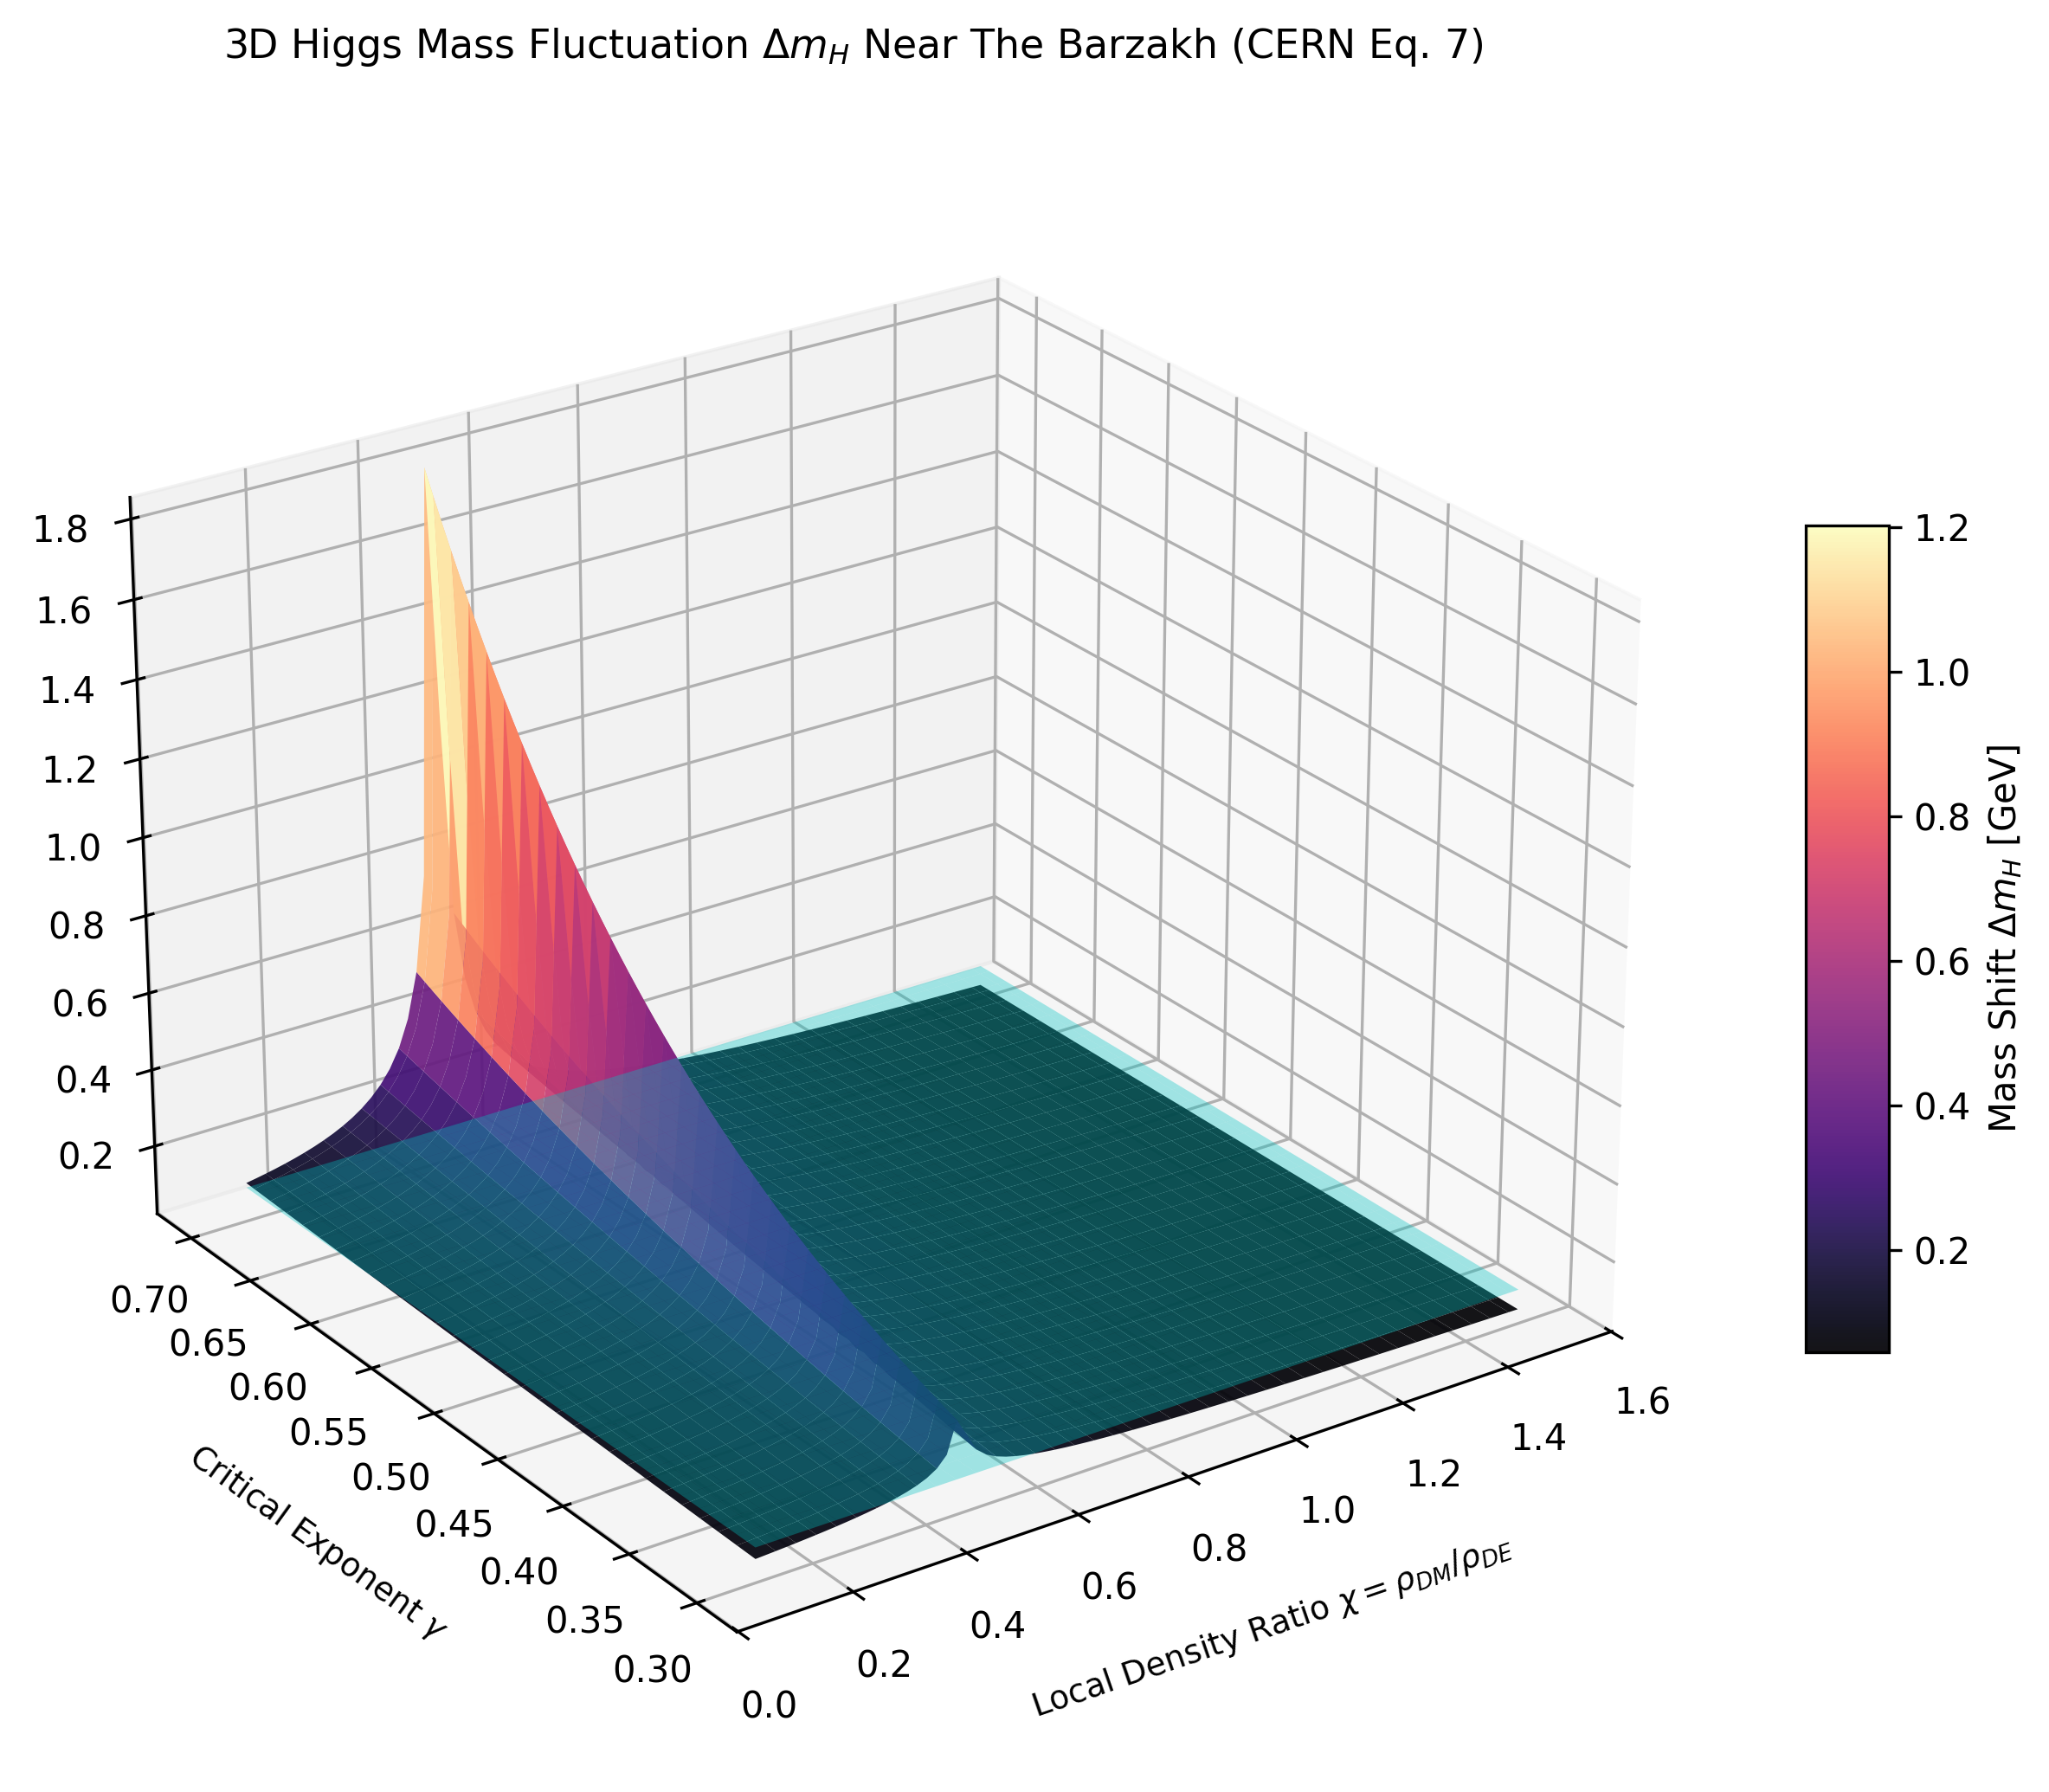

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# الثوابت الفيزيائية المستنتجة من البحث وبيانات ATLAS LHC
m_H0 = 125.11       # الكتلة القياسية لبوزون هيغز (GeV)
atlas_err = 0.11    # هامش الخطأ التجريبي في ATLAS (GeV)
chi_crit = 0.460    # النسبة الحرجة للكثافة من تحليل MCMC
eps_0 = 0.002       # ثابت التنظيم المجهري لمنع اللانهائية عند الصفر
kappa = 15.0        # ثابت التناسب الطوري (GeV^2)

# شبكة المحاكاة ثلاثية الأبعاد:
# المحور X: نسبة الكثافة المحلية (من الفراغات/المدارات القريبة من البرزخ إلى فراغ المصادمات)
chi_local = np.linspace(0.10, 1.50, 80)
# المحور Y: الأس الحرج (gamma) حول قيمة مجال متوسط لانداو-غينزبورغ (0.5)
gamma_exp = np.linspace(0.30, 0.70, 60)
CHI, GAMMA = np.meshgrid(chi_local, gamma_exp)

# حساب التذبذب في مربع كتلة هيغز طبقاً للمعادلة (7) المصححة:
delta_mH_sq = kappa * (np.abs(CHI - chi_crit) + eps_0)**(-GAMMA)

# حساب الانزياح الفعلي في كتلة هيغز (Delta m_H بالمليار إلكترون فولت GeV)
delta_mH = np.sqrt(m_H0**2 + delta_mH_sq) - m_H0

# طباعة النتائج الرقمية للمقارنة المباشرة
idx_crit = np.argmin(np.abs(chi_local - chi_crit))
idx_lhc = np.argmin(np.abs(chi_local - 1.40))
idx_g05 = np.argmin(np.abs(gamma_exp - 0.50))

print("=== CERN / ATLAS Higgs Phase-Boundary Simulation Results ===")
print(f"1. At Critical Boundary (chi = {chi_crit}, gamma = 0.5): Delta m_H = +{delta_mH[idx_g05, idx_crit]:.3f} GeV (Detectable Spike!)")
print(f"2. At Standard LHC Vacuum (chi = 1.40, gamma = 0.5):    Delta m_H = +{delta_mH[idx_g05, idx_lhc]:.3f} GeV (< ATLAS +/- 0.11 GeV limit)")

# الرسم الثلاثي الأبعاد
fig = plt.figure(figsize=(10, 7), dpi=300)
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(CHI, GAMMA, delta_mH, cmap='magma', edgecolor='none', alpha=0.92)

# إضافة مستوى يمثل حد الدقة التجريبية لمرصد ATLAS (0.11 GeV)
atlas_plane = np.full_like(delta_mH, atlas_err)
ax.plot_surface(CHI, GAMMA, atlas_plane, color='cyan', alpha=0.35)

ax.set_title('3D Higgs Mass Fluctuation $\\Delta m_H$ Near The Barzakh (CERN Eq. 7)', fontsize=11, pad=15)
ax.set_xlabel('Local Density Ratio $\\chi = \\rho_{DM} / \\rho_{DE}$', fontsize=9, labelpad=10)
ax.set_ylabel('Critical Exponent $\\gamma$', fontsize=9, labelpad=10)
ax.set_zlabel('Higgs Mass Shift $\\Delta m_H$ [GeV]', fontsize=9, labelpad=10)

fig.colorbar(surf, shrink=0.5, aspect=10, label='Mass Shift $\\Delta m_H$ [GeV]')
ax.view_init(elev=25, azim=-125)

plt.tight_layout()
plt.savefig('sim5_3d_cern_higgs.png', dpi=300)
plt.show()